# Sensitivity Analysis

Tests how total ECL responds to changes in key assumptions: scenario probability weights,
the PD stress multiplier, and LGD. Also breaks ECL down by stage to show where stress
impact concentrates. Results show which assumptions the ECL number is most dependent on,
which is where a model reviewer would focus validation effort.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/processed/ecl_scenario_results.csv')
total_ead = df['EAD'].sum()
df.shape

(10000, 39)

In [2]:
stage_summary = df.groupby('stage')[['ECL_Base', 'ECL_Adverse', 'ECL_Severe', 'ECL_weighted']].sum().round(0)
stage_summary['Severe_vs_Base_x'] = (stage_summary['ECL_Severe'] / stage_summary['ECL_Base']).round(2)
stage_summary

,ECL_Base,ECL_Adverse,ECL_Severe,ECL_weighted,Severe_vs_Base_x
stage,,,,,
Stage 1,1999034.0,2998552.0,4997586.0,2598744.0,2.50
Stage 2,5853954.0,8239319.0,10455145.0,7029683.0,1.79
Stage 3,71507.0,72698.0,72698.0,71983.0,1.02


In [3]:
totals = {
    'Base': df['ECL_Base'].sum(),
    'Adverse': df['ECL_Adverse'].sum(),
    'Severe': df['ECL_Severe'].sum(),
}

weight_sets = {
    'Optimistic (80/15/5)': {'Base': 0.80, 'Adverse': 0.15, 'Severe': 0.05},
    'Current (60/30/10)': {'Base': 0.60, 'Adverse': 0.30, 'Severe': 0.10},
    'Pessimistic (40/40/20)': {'Base': 0.40, 'Adverse': 0.40, 'Severe': 0.20},
    'Crisis-heavy (20/40/40)': {'Base': 0.20, 'Adverse': 0.40, 'Severe': 0.40},
}

rows = []
for name, w in weight_sets.items():
    ecl = sum(totals[s] * p for s, p in w.items())
    rows.append({'Weights': name, 'Weighted ECL': round(ecl), 'Coverage': round(ecl / total_ead, 4)})

pd.DataFrame(rows)

,Weights,Weighted ECL,Coverage
0,Optimistic (80/15/5),8812453,0.0889
1,Current (60/30/10),9700411,0.0979
2,Pessimistic (40/40/20),10799112,0.1090
3,Crisis-heavy (20/40/40),12319298,0.1243


In [4]:
rows = []
for m in [1.0, 1.5, 2.0, 2.5, 3.0, 4.0]:
    pd_stressed = np.clip(df['PD_used'] * m, 0, 1)
    ecl = (pd_stressed * df['LGD'] * df['EAD']).sum()
    rows.append({'PD multiplier': m, 'Total ECL': round(ecl), 'Coverage': round(ecl / total_ead, 4)})

pd.DataFrame(rows)

,PD multiplier,Total ECL,Coverage
0,1.0,7924495,0.0800
1,1.5,11310569,0.1142
2,2.0,13681948,0.1381
3,2.5,15525429,0.1567
4,3.0,17098091,0.1726
5,4.0,19814392,0.2000


In [5]:
rows = []
for shift in [-0.10, -0.05, 0.0, 0.05, 0.10]:
    lgd_shifted = np.clip(df['LGD'] + shift, 0, 1)
    ecl = (df['PD_used'] * lgd_shifted * df['EAD']).sum()
    rows.append({'LGD shift (pp)': shift, 'Base ECL': round(ecl), 'Coverage': round(ecl / total_ead, 4)})

pd.DataFrame(rows)

,LGD shift (pp),Base ECL,Coverage
0,-0.10,6312364,0.0637
1,-0.05,7118429,0.0718
2,0.00,7924495,0.0800
3,0.05,8730560,0.0881
4,0.10,9536626,0.0963


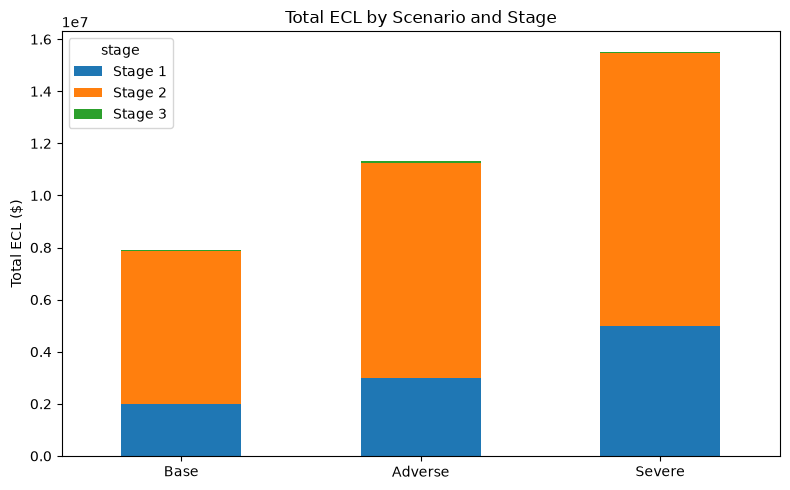

In [6]:
plot_df = df.groupby('stage')[['ECL_Base', 'ECL_Adverse', 'ECL_Severe']].sum().T
plot_df.index = ['Base', 'Adverse', 'Severe']

plot_df.plot(kind='bar', stacked=True, figsize=(8, 5))
plt.title('Total ECL by Scenario and Stage')
plt.ylabel('Total ECL ($)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('../docs/ecl_by_scenario.png', dpi=150)
plt.show()

## Key Findings

- Total ECL is most sensitive to the PD stress multiplier and to LGD, which scales ECL roughly proportionally. Scenario weights matter less because they only blend three totals.
- Stress impact is concentrated in Stage 2, which holds about 74% of Base ECL and drives most of the Base-to-Severe increase.
- Severe ECL is about 1.96x Base rather than 2.5x because PD is capped at 100%. Stage 3 loans are already near the cap and barely move (1.02x).
- Limitation: multipliers, scenario probabilities, and LGD are illustrative assumptions rather than values estimated from historical data.